Q1. Camera 5x5 = 25 points


(a) In the Assignment 1, Q1, find the coordinates of the centre of the swinging load,
𝑜1(𝑥, 𝑦, 𝑧) for all frames in training set rgb_train_val_swingingload.avi. Use the 𝑀𝑖𝑛𝑡
obtained in the Lab. Plot the 3D coordinates of swinging load for all frames.

Number of npy files: 900

0: 480x640 1 box, 275.9ms
Speed: 9.2ms preprocess, 275.9ms inference, 12.9ms postprocess per image at shape (1, 3, 480, 640)

0: 480x640 1 box, 51.1ms
Speed: 2.4ms preprocess, 51.1ms inference, 0.8ms postprocess per image at shape (1, 3, 480, 640)

0: 480x640 1 box, 51.9ms
Speed: 4.5ms preprocess, 51.9ms inference, 0.8ms postprocess per image at shape (1, 3, 480, 640)

0: 480x640 1 box, 56.8ms
Speed: 1.6ms preprocess, 56.8ms inference, 1.4ms postprocess per image at shape (1, 3, 480, 640)

0: 480x640 1 box, 52.4ms
Speed: 1.7ms preprocess, 52.4ms inference, 1.4ms postprocess per image at shape (1, 3, 480, 640)

0: 480x640 1 box, 57.4ms
Speed: 1.8ms preprocess, 57.4ms inference, 1.4ms postprocess per image at shape (1, 3, 480, 640)

0: 480x640 1 box, 57.3ms
Speed: 1.5ms preprocess, 57.3ms inference, 1.6ms postprocess per image at shape (1, 3, 480, 640)

0: 480x640 1 box, 50.1ms
Speed: 2.0ms preprocess, 50.1ms inference, 0.8ms postprocess per image at shape (1, 3

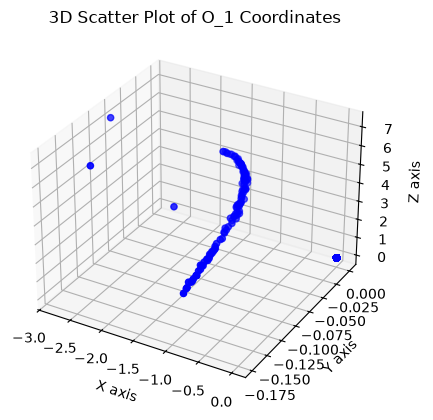

In [2]:
# Prep - Retrieve video and model from q1/data/train and q1/model

import glob
import json
import os
import cv2
from ultralytics import YOLO
import numpy as np
import matplotlib.pyplot as plt

model = YOLO("../assignment_1/q1/model/YOLO_swinging_load.pt")
video = "../assignment_1/q1/data/train/color_video/color_video.avi"

cap = cv2.VideoCapture(video)
if not cap.isOpened():
    print("Error: Cannot open video file!")
    exit()

npy_files = sorted(glob.glob("../assignment_1/q1/data/train/depth_raw/*.npy"))
print(f"Number of npy files: {len(npy_files)}")

depth_scale_json_file = "../assignment_1/q1/data/train/depth_scale_json/depth_scale.json"
with open(depth_scale_json_file, 'r') as f:
    depth_scale = json.load(f)["depth_scale"]

center_coords = []

# Open video, store 3D center coordinates in center_coords[]

idx = 0
while cap.isOpened() and idx < len(npy_files):
    ret, frame = cap.read()
    if not ret:
        print("Video frame is empty or video has played till completion")
        break
    
    results = model(frame)
    cx,cy = results[0].boxes.xywh[0,:2].cpu().numpy().astype(int)  
    
    # Find depth at center point
    depth_file = np.load(npy_files[idx]) 
    idx += 1
    depth = np.mean(depth_file[cy, cx]) * depth_scale 
    
    center = np.array([
        [cx],
        [cy],
        [depth]
    ])

    center_coords.append(center)

cap.release()
cv2.destroyAllWindows()

# A - Use intrinsic matrix From Lab 3 to convert center points to 3D  coordinates relative to camera, store in O_1_coords[]

M_int = np.array([
    [1.72992620e+03, 0.00000000e+00, 1.06974682e+03],
    [0.00000000e+00, 2.66589388e+03, 2.59554251e+02],
    [0.00000000e+00, 0.00000000e+00, 1.00000000e+00]
])

O_1_coords = []

for center in center_coords :
    pixel_coords = np.array([[center[0][0]], [center[1][0]], [1]])
    camera_coords = np.linalg.inv(M_int) @ pixel_coords * center[2][0]
    O_1_coords.append(camera_coords)
    print("Camera Coordinates:", camera_coords.flatten())

# Plot all O_1_coords in 3D space using matplotlib as blue points
O_1_coords = np.array(O_1_coords).squeeze()  # Convert list of arrays to a single 2D array
fig, ax = plt.subplots(subplot_kw={"projection": "3d"})
ax.scatter(O_1_coords[:, 0], O_1_coords[:, 1], O_1_coords[:, 2], c='b', marker='o')
ax.set_xlabel('X axis')
ax.set_ylabel('Y axis')
ax.set_zlabel('Z axis')
plt.title('3D Scatter Plot of O_1 Coordinates')
plt.show()

(b) Say, the default intrinsic matrix of L515 is

$$M_d = \begin{bmatrix} 1342 & 0 & 325 \\  0 & 1342 & 235 \\  0 & 0 & 1 \end{bmatrix}$$

Use this matrix to find the 3D coordinates of the center of swinging load for all frames ($o_2$) and plot them.

Number of npy files: 900

0: 480x640 1 box, 80.6ms
Speed: 2.1ms preprocess, 80.6ms inference, 1.5ms postprocess per image at shape (1, 3, 480, 640)

0: 480x640 1 box, 66.6ms
Speed: 2.2ms preprocess, 66.6ms inference, 1.5ms postprocess per image at shape (1, 3, 480, 640)

0: 480x640 1 box, 69.6ms
Speed: 1.4ms preprocess, 69.6ms inference, 1.5ms postprocess per image at shape (1, 3, 480, 640)

0: 480x640 1 box, 61.9ms
Speed: 1.8ms preprocess, 61.9ms inference, 1.5ms postprocess per image at shape (1, 3, 480, 640)

0: 480x640 1 box, 63.5ms
Speed: 1.6ms preprocess, 63.5ms inference, 1.4ms postprocess per image at shape (1, 3, 480, 640)

0: 480x640 1 box, 60.9ms
Speed: 2.6ms preprocess, 60.9ms inference, 1.6ms postprocess per image at shape (1, 3, 480, 640)

0: 480x640 1 box, 61.9ms
Speed: 1.7ms preprocess, 61.9ms inference, 1.4ms postprocess per image at shape (1, 3, 480, 640)

0: 480x640 1 box, 59.8ms
Speed: 1.9ms preprocess, 59.8ms inference, 1.4ms postprocess per image at shape (1, 3, 4

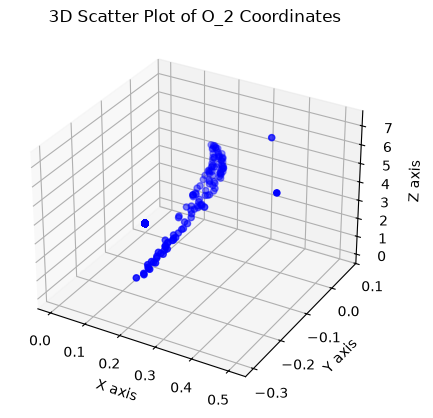

In [3]:
# Q1 B, copy code from above, but use standard matrix to convert center points to 3D world coordinates relative to camera, store in O_2_coords[]

# Prep - Retrieve video and model from q1/data/train and q1/model

import glob
import json
import os
import cv2
from ultralytics import YOLO
import numpy as np
import matplotlib.pyplot as plt

model = YOLO("../assignment_1/q1/model/YOLO_swinging_load.pt")
video = "../assignment_1/q1/data/train/color_video/color_video.avi"

cap = cv2.VideoCapture(video)
if not cap.isOpened():
    print("Error: Cannot open video file!")
    exit()

npy_files = sorted(glob.glob("../assignment_1/q1/data/train/depth_raw/*.npy"))
print(f"Number of npy files: {len(npy_files)}")

depth_scale_json_file = "../assignment_1/q1/data/train/depth_scale_json/depth_scale.json"
with open(depth_scale_json_file, 'r') as f:
    depth_scale = json.load(f)["depth_scale"]

center_coords = []

# Open video, store 3D center coordinates in center_coords[]

idx = 0
while cap.isOpened() and idx < len(npy_files):
    ret, frame = cap.read()
    if not ret:
        print("Video frame is empty or video has played till completion")
        break
    
    results = model(frame)
    cx,cy = results[0].boxes.xywh[0,:2].cpu().numpy().astype(int)  
    
    # Find depth at center point
    depth_file = np.load(npy_files[idx]) 
    idx += 1
    depth = np.mean(depth_file[cy, cx]) * depth_scale 
    
    center = np.array([
        [cx],
        [cy],
        [depth]
    ])

    center_coords.append(center)

cap.release()
cv2.destroyAllWindows()

# B - Use given matrix to convert center points to 3D coordinates relative to camera, store in O_2_coords[]

M_int = np.array([
    [1.342e+03, 0.00e+00, 3.25e+02],
    [0.00e+00, 1.342e+03, 2.35e+02],
    [0.00e+00, 0.00e+00, 1.00e+00]
])

O_2_coords = []

for center in center_coords :
    pixel_coords = np.array([[center[0][0]], [center[1][0]], [1]])
    camera_coords = np.linalg.inv(M_int) @ pixel_coords * center[2][0]
    O_2_coords.append(camera_coords)
    print("Camera Coordinates:", camera_coords.flatten())

# Plot all O_2_coords in 3D space using matplotlib as blue points
O_2_coords = np.array(O_2_coords).squeeze()  # Convert list of arrays to a single 2D array
fig, ax = plt.subplots(subplot_kw={"projection": "3d"})
ax.scatter(O_2_coords[:, 0], O_2_coords[:, 1], O_2_coords[:, 2], c='b', marker='o')
ax.set_xlabel('X axis')
ax.set_ylabel('Y axis')
ax.set_zlabel('Z axis')
plt.title('3D Scatter Plot of O_2 Coordinates')
plt.show()

(c) Which intrinsic matrix — $M_{\text{int}}$ or $M_d$, is accurate? Give reasons for your answer.

In [ ]:
# Answer: Clearly the calculated intrinsic matrix is horribly incorrect and not accurate (it says load is left, while its actually right), 
# while the default matrix is much more accurate.

(d) From the data set obtained from (a) and (b) i.e. 𝑜1 𝑎𝑛𝑑 𝑜2. Implement ML model that
learns the function parameters such that 𝑓𝜃(𝑜1) = 𝑜2∗. Explain the results by
finding/demonstrating the relevant KPIs.

Mean Squared Error (MSE): 0.0009
Root Mean Squared Error (RMSE): 0.0308
R2 Score: 0.7402


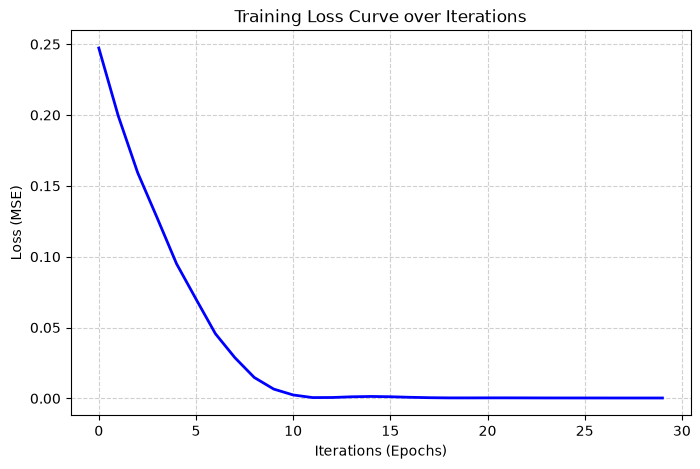

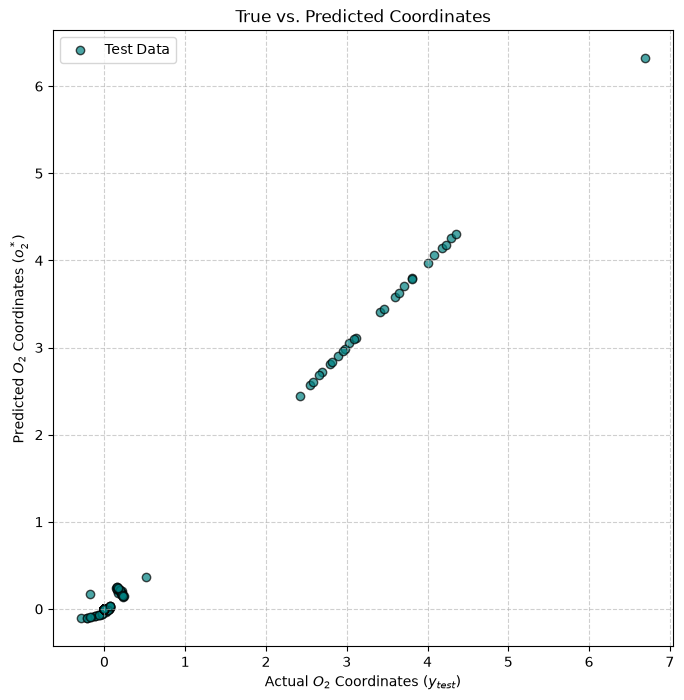

In [4]:
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.neural_network import MLPRegressor
from sklearn.metrics import mean_squared_error, r2_score


# Split data into training and testing sets (80% train, 20% test)
X_train, X_test, y_train, y_test = train_test_split(O_1_coords, O_2_coords, test_size=0.2, random_state=42)

# Initialize a simple Neural Network Regressor
# With two hidden layers of 64 neurons each
mlp_model = MLPRegressor(hidden_layer_sizes=(64, 64), 
                           activation='relu', 
                           solver='adam', 
                           max_iter=1000, 
                           random_state=42)

# Train (fit) the model to learn the parameters theta
mlp_model.fit(X_train, y_train)

# Generate predictions o_2^* on the test set
o2_star_test = mlp_model.predict(X_test)

# Calculate KPIs
mse = mean_squared_error(y_test, o2_star_test)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, o2_star_test)

print(f"Mean Squared Error (MSE): {mse:.4f}")
print(f"Root Mean Squared Error (RMSE): {rmse:.4f}")
print(f"R2 Score: {r2:.4f}")

import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.plot(mlp_model.loss_curve_, color='b', linewidth=2)
plt.title("Training Loss Curve over Iterations")
plt.xlabel("Iterations (Epochs)")
plt.ylabel("Loss (MSE)")
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()


plt.figure(figsize=(8, 8))
plt.scatter(y_test, o2_star_test, color='teal', alpha=0.7, edgecolors='k', label='Test Data')
plt.title("True vs. Predicted Coordinates")
plt.xlabel("Actual $O_2$ Coordinates ($y_{test}$)")
plt.ylabel("Predicted $O_2$ Coordinates ($o_2^*$)")
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

(e) Find the Euclidean error between (i) 𝑜1 𝑎𝑛𝑑 𝑜2 and (ii) 𝑜1 𝑎𝑛𝑑 𝑜2∗. Make the
interpretations of the results that you obtain

Mean Euclidean Error (MEE) between O_1_coords and O_2_coords: 0.2107 meters
Root Mean Square Error (RMSE) between O_1_coords and O_2_coords: 0.5683 meters
Mean Euclidean Error (MEE) between o1_test and o2_star_test: 0.2325 meters
Root Mean Square Error (RMSE) between o1_test and o2_star_test: 0.6165 meters


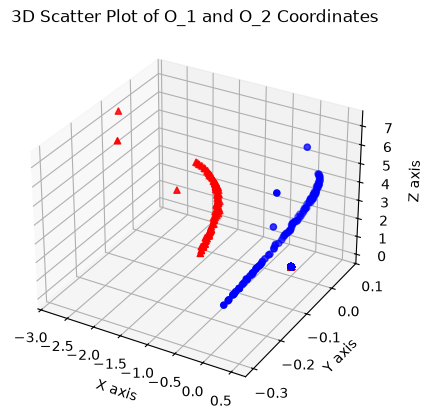

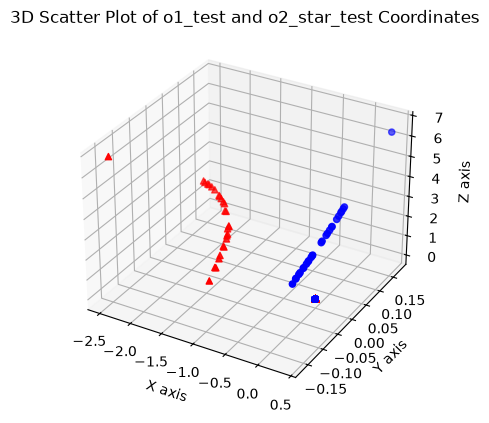

In [5]:
# Q1 E (i)

# Mean Euclidean Error (MEE) between O_1_coords and O_2_coords
import numpy as np

# i)
errors = np.linalg.norm(O_2_coords - O_1_coords, axis=1)
mean_error = np.mean(errors)
print(f"Mean Euclidean Error (MEE) between O_1_coords and O_2_coords: {mean_error:.4f} meters")
errors_2 = errors**2
rmse = np.sqrt(np.mean(errors_2))
print(f"Root Mean Square Error (RMSE) between O_1_coords and O_2_coords: {rmse:.4f} meters")

# ii)
errors = np.linalg.norm(o2_star_test - X_test, axis=1)
mean_error = np.mean(errors)
print(f"Mean Euclidean Error (MEE) between o1_test and o2_star_test: {mean_error:.4f} meters")
errors_2 = errors**2
rmse = np.sqrt(np.mean(errors_2))
print(f"Root Mean Square Error (RMSE) between o1_test and o2_star_test: {rmse:.4f} meters")



# i)
fig, ax = plt.subplots(subplot_kw={"projection": "3d"})
ax.scatter(O_2_coords[:, 0], O_2_coords[:, 1], O_2_coords[:, 2], c='b', marker='o')
ax.scatter(O_1_coords[:, 0], O_1_coords[:, 1], O_1_coords[:, 2], c='r', marker='^')
ax.set_xlabel('X axis')
ax.set_ylabel('Y axis')
ax.set_zlabel('Z axis')
plt.title('3D Scatter Plot of O_1 and O_2 Coordinates')
plt.show()

# ii)
fig, ax = plt.subplots(subplot_kw={"projection": "3d"})
ax.scatter(o2_star_test[:, 0], o2_star_test[:, 1], o2_star_test[:, 2], c='b', marker='o')
ax.scatter(X_test[:, 0], X_test[:, 1], X_test[:, 2], c='r', marker='^')
ax.set_xlabel('X axis')
ax.set_ylabel('Y axis')
ax.set_zlabel('Z axis')
plt.title('3D Scatter Plot of o1_test and o2_star_test Coordinates')
plt.show()

Q2. Lidar 10+15 = 25 points

(a) Use Ouster lidar in Lab to record the trajectory of swinging load. Find the center
of swinging load for all frames, and plot them. 

In [ ]:
# Prep, get lidar data from pcap file within angles

pcap_file = "lab_4/lidar-pcd processing-2026 class/swinging_load.pcap" 
json_file = "lab_4/lidar-pcd processing-2026 class/swinging_load.json"
csv_directory = "assignment_2/q2/a/"

# Convert pcap to CSV:
# https://docs.ouster.com/sdk-docs/examples/python/conversion.html#pcaps-to-csv
# Move CSV's into assignment2/q2/a/raw

import numpy as np
import pandas as pd
from pathlib import Path

# Use Pandas to clean away all values except row, destaggered image column, range, x, y, z

input_dir = Path("q2/a/raw")
output_dir = input_dir / "cleaned"
output_dir.mkdir(exist_ok=True)
csv_files = list(input_dir.glob("*.csv"))

if not csv_files:
    raise ValueError(f"No CSV files found in {input_dir}!")

col_indices = [1, 2, 6, 9, 10, 11]
col_names = ["ROW", "DESTAGGERED IMAGE COLUMN", "RANGE (mm)", "X1 (m)", "Y1 (m)", "Z1 (m)"]

print(f"Found {len(csv_files)} CSV files to process...")

for file_path in csv_files:
    try:
        # Read CSV with header=None to access columns by index, skipping the '#' comment lines
        df = pd.read_csv(file_path, header=None, comment='#')
        
        # Select the columns by their integer position and assign proper names
        df_cleaned = df[col_indices].copy()
        df_cleaned.columns = col_names
        
        # Save the cleaned file to the output directory
        output_file_path = output_dir / file_path.name
        df_cleaned.to_csv(output_file_path, index=False)
        
    except Exception as e:
        print(f"Error processing {file_path.name}: {e}")

print(f"Processing complete! Cleaned files saved to: {output_dir}")


Found 101 CSV files to process...
Processing complete! Cleaned files saved to: q2\a\cleaned


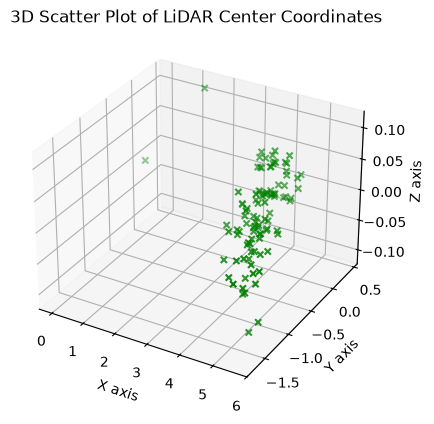

In [6]:
# Q2 A

import numpy as np
import matplotlib.pyplot as plt

frames = []
for i in range(101):
    frame = np.loadtxt(f'q2/a/cleaned/output_s0_{i}.csv', delimiter=',', skiprows=1)
    frame = frame.reshape((64, -1, frame.shape[1])) # 64 rows per column, 1024 columns per frame (360 degrees)
    frames.append(frame)

# Only care about ROI, which is between 180 and 270 degrees, so we filter frames to only show those
# Assuming col 0 = 0 degress, and col 1024 = 360, then

start_col = int((180 / 360) * 1024)
end_col = int((270 / 360) * 1024)

filtered_frames = []

for frame in frames:
    filtered_frame = frame[:, start_col:end_col, :]
    filtered_frames.append(filtered_frame)


# Now we find gathering of points where depth values (range) change across two frames, timestep 0 and 1.
# If a change has occured between some points, take those points, arrange them in sequential array, and find median position
# That position is center point

center_points = []
threshold_mm = 50 # To avoid sensor noise 

for i in range(len(filtered_frames) - 1):
    curr_frame = filtered_frames[i]
    next_frame = filtered_frames[i+1]
    
    # Feature index 2 is RANGE (mm)
    range_diff = np.abs(next_frame[:, :, 2] - curr_frame[:, :, 2])

    # Create mask where range changed significantly
    moving_mask = range_diff > threshold_mm

    # Extract XYZ coordinates of the points that moved
    # XYZ correspond to features 3, 4, 5 (X1, Y1, Z1)
    moving_xyz = curr_frame[:, :, 3:6][moving_mask]
    
    if len(moving_xyz) > 0:
        # Calculate median center point across the XYZ dimensions (axis=0)
        center_point = np.median(moving_xyz, axis=0) # Returns [X, Y, Z]
        center_points.append(center_point)

center_points = np.array(center_points)

fig, ax = plt.subplots(subplot_kw={"projection": "3d"})
ax.scatter(center_points[:, 0], center_points[:, 1], center_points[:, 2], c='g', marker='x')
ax.set_xlabel('X axis')
ax.set_ylabel('Y axis')
ax.set_zlabel('Z axis')
plt.title('3D Scatter Plot of LiDAR Center Coordinates')
plt.show()




(b) Leverage KISS ICP to find the pose of center of load in consecutive lidar frame.

Q3. Camera-Lidar fusion 10 + 15 = 25 points

KITTI data set is comprehensive data set used for benchmarking different algortithms.

(a) Get familiar with the KITTI data set. There are multiple cameras, and Lidar used.
It contains the rich information about - images taken from cameras, point cloud
taken from lidar, camera matrices. Illustrate your understanding in
presentation.

In [ ]:
# See presentation for understanding 

(b) Use the training dataset. Perform the lidar-camera fusion. Choose random five images from the training/

(i) Project them on the lidar frame or viseversa.

(ii) Detect the object in the scene, place bounding box around it,
measure the distance of object (shown by color bar) and display near
the bounding box

(iii) Validate your estimation of distance with ground truth

Q4. Autonomous navigation and slip estimationPoints: $10 + 10 + 5 = 25\text{ points}$

Webots - https://cyberbotics.com/ is an open source light weight platform to simulate robotics, perception, and control. This give us the platform to conceptualize and simulate downstream tasks.Leveraging Webots perform the following tasks:

(a) Baseline: Instantiate a robot, and equip it with sensors – camera, lidar, accelerometer, gyro, GPS, IMU etc on it. Then navigate in the world and move towards a predefined object goal (e.g. cylinder sphere or .. with predefined colour) with collision avoidance. At each time record the sensors data e.g. encoder data, lidar data, camera IMU for example. Compute the longitudinal slip ($s_{long}$) as follows:$$s\_long = \frac{v_{enc} - v_x}{v_x}$$Where $v_{enc}$ is the velocity obtained from encoder = $\omega r$; $\omega \text{ and } r$ are the angular velocity and radius of wheel.$v_x$ is the ground truth given from lidar, or the webot simulation world. Feel free to choose

In [ ]:
# Unable to open WeBot

(b) Low slip conditions: Simulate lower slip of your choice (varying the friction), then
repeat the same object goal navigation as above. Recalculate the longitudinal slip

In [ ]:
# Blank due to WeBot not opening, unable to complete

(c) Plot the slip for both cases along the trajectory that the robot navigates

In [ ]:
# Blank due to WeBot not opening, unable to complete